# 02 · From pressure tags to a fouling rate

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p04_tide_fouling/notebooks/02_from_tags_to_fouling.ipynb)

The record logs flows, pressures and a temperature every few seconds. None of them is "fouling". This
notebook builds the one number every later test uses: the **fouling rate of each filtration
stretch**, in per cent of membrane resistance per hour.

**Data:** a public seawater ultrafiltration (UF) pilot record, pre-treatment for a reverse-osmosis pilot, 2012–2015: Zenodo [4630769](https://zenodo.org/records/4630769), also Dryad [doi:10.5068/D1310B](https://doi.org/10.5068/D1310B), CC0. The site is not named here. The notebooks read the tables committed in `results/`; the 356 MB raw archive is needed only where a cell says so. This notebook also reads a 12-hour excerpt of one run, committed as
`results/excerpt_20150303_12h.parquet` (the record is CC0).

Script version: `step2_segments.py`, `chemai/features/uf_segments.py` · record: `VALIDATION.md`, section 2.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 4 pull request is merged, use "p04-tide-fouling"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P4 = ROOT / "projects" / "p04_tide_fouling"
RES = P4 / "results"

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, SUN = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#f2c14e"

def load(name):
    """A committed result file from projects/p04_tide_fouling/results/."""
    return json.loads((RES / name).read_text())

## 1. The physics: resistance, not pressure

Through a membrane, flux follows Darcy's law: J = TMP / (μ · R). Rearranged, the membrane's hydraulic
resistance is

$$R \;\propto\; \frac{\text{TMP}}{\mu(T)\,Q}$$

with TMP the pressure across it, Q the flow (membrane area is fixed, and not in the record) and μ
the water's viscosity. Fouling is R rising. Pressure alone would mislead twice: it rises when the
operators raise the flow, and it rises when the water cools — viscosity changes about 2.5 % per °C:

In [2]:
from chemai.features.uf_segments import (configuration, cut_segments, resistance_index,
                                         segment_table, water_viscosity)
t = np.array([12, 16, 20, 24, 28])
pd.DataFrame({"water °C": t, "viscosity, mPa·s": water_viscosity(t) * 1e3,
              "vs 20 °C": water_viscosity(t) / water_viscosity(20)}).round(3)

,water °C,"viscosity, mPa·s",vs 20 °C
0,12,1.230,1.228
1,16,1.107,1.105
2,20,1.002,1.000
3,24,0.911,0.910
4,28,0.833,0.831


The fouling rate of a stretch is the slope of ln R in time, × 100: per cent per hour. A log keeps
it independent of R's unknown scale (membrane area and age cancel).

## 2. Twelve hours of one run

4,320 samples, logged every 10 s, 2015-03-03 14:43 to 02:43


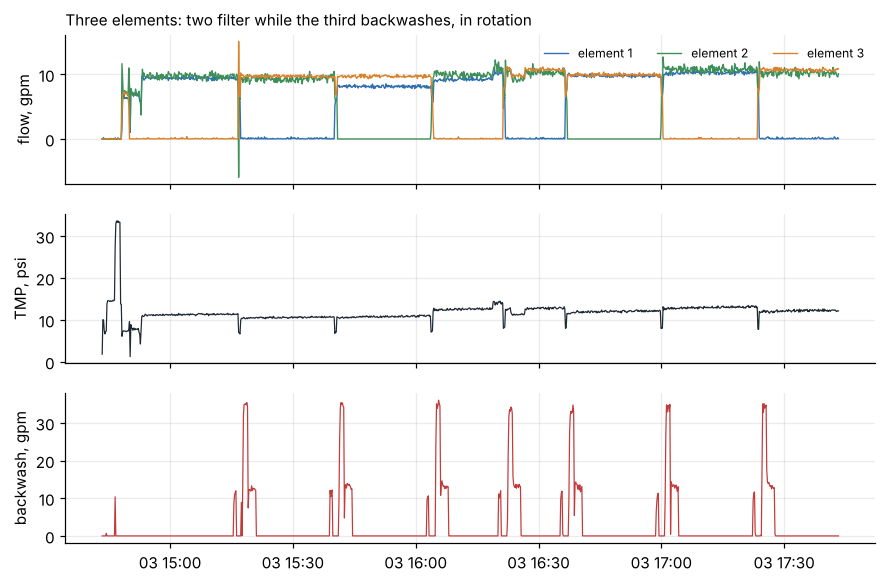

In [3]:
x = pd.read_parquet(RES / "excerpt_20150303_12h.parquet").astype(float)
print(f"{len(x):,} samples, logged every {(x.index[1] - x.index[0]).total_seconds():.0f} s, "
      f"{x.index[0]:%Y-%m-%d %H:%M} to {x.index[-1]:%H:%M}")
w = x[x.index < x.index[0] + pd.Timedelta(hours=3)]
fig, ax = plt.subplots(3, 1, figsize=(9.5, 6), sharex=True)
for k, c in zip(("q_e1", "q_e2", "q_e3"), (BLUE, GREEN, ORANGE)):
    ax[0].plot(w.index, w[k], lw=0.9, color=c, label=f"element {k[-1]}")
ax[0].set_ylabel("flow, gpm"); ax[0].legend(frameon=False, ncol=3, fontsize=8, loc="upper right")
ax[1].plot(w.index, w.p_uf_in - w.p_uf_out, color=INK, lw=0.8); ax[1].set_ylabel("TMP, psi")
ax[2].plot(w.index, w.q_bw, color=RED, lw=0.8); ax[2].set_ylabel("backwash, gpm")
ax[0].set_title("Three elements: two filter while the third backwashes, in rotation", loc="left", fontsize=10)
plt.show()

The pilot rotates three elements: two filter while the third backwashes, every 20 minutes or so.
Each change of pair is a new configuration, and the pressure jumps with it. So the record is cut
into **segments**: stretches with one configuration, a steady flow and a clean clock, trimmed of
their first 3 minutes and last minute of transients, 10 minutes or longer.

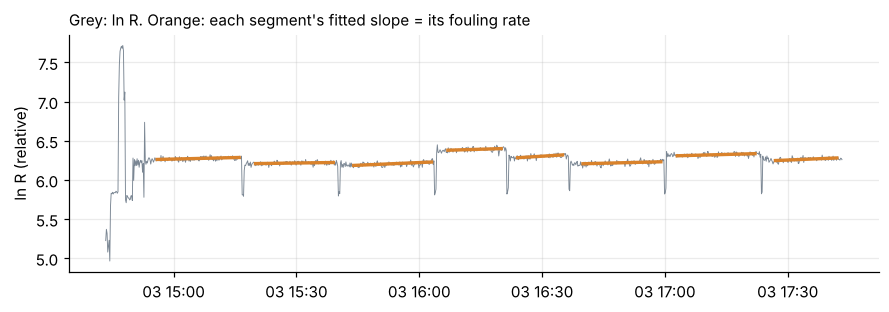

In [4]:
lnr = np.log(resistance_index(w))
fig, ax = plt.subplots(figsize=(9.5, 2.8))
ax.plot(w.index, lnr, color=MUTED, lw=0.6)
for a, b in cut_segments(w):
    s = lnr.iloc[a:b + 1].resample("60s").median().dropna()
    h = (s.index - s.index[0]).total_seconds() / 3600
    k, c = np.polyfit(h, s.to_numpy(), 1)
    ax.plot(s.index, c + k * h, color=ORANGE, lw=2.2)
ax.set_ylabel("ln R (relative)")
ax.set_title("Grey: ln R. Orange: each segment's fitted slope = its fouling rate", loc="left", fontsize=10)
plt.show()

Within a segment ln R climbs; a backwash knocks it back; the next pair starts from its own level.
The level jumps are why a long-run trend of pressure says little — and why the **slope inside each
segment** is the measurement.

`segment_table` does this for a whole run. On the excerpt it reproduces the committed table:

In [5]:
mine = segment_table(x, "20150303.csv")
seg = pd.read_parquet(RES / "segments.parquet")
theirs = seg[(seg.run == "20150303.csv") & (seg.t_start < x.index[-1])]
m = mine.merge(theirs, on="t_start", suffixes=("_excerpt", "_committed"))
print(f"{len(mine)} segments from the excerpt; {len(m)} match the committed table; "
      f"largest difference {(m.fouling_pct_h_excerpt - m.fouling_pct_h_committed).abs().max():.1e} %/h")
mine[["t_start", "minutes", "config", "n_online", "fouling_pct_h", "fouling_se_pct_h", "temp_c"]].head(8).round(2)

32 segments from the excerpt; 32 match the committed table; largest difference 6.1e-05 %/h


,t_start,minutes,config,n_online,fouling_pct_h,fouling_se_pct_h,temp_c
0,2015-03-03 14:56:14.804448311,19.83,3,2,7.57,2.32,15.87
1,2015-03-03 15:20:14.804217893,19.33,6,2,4.34,2.19,15.93
2,2015-03-03 15:44:04.804310149,19.00,5,2,13.64,3.50,15.97
3,2015-03-03 16:07:24.804336293,13.33,3,2,9.50,3.36,15.99
4,2015-03-03 16:24:54.804355433,11.00,6,2,19.47,4.90,16.01
5,2015-03-03 16:40:14.804429050,19.00,5,2,7.96,2.08,16.02
6,2015-03-03 17:03:34.803504060,19.17,3,2,8.44,2.20,16.04
7,2015-03-03 17:27:04.804156782,20.50,6,2,6.70,2.12,16.03


(The one segment the excerpt does not match is cut short by the excerpt's end.)

## 3. The whole record: 14,998 segments

14,998 segments in 106 runs and 86 episodes; median 13.2 min long
fouling rate: median 13.2 %/h, middle half 8.7-18.6; negative in 3.7% of segments
one segment's own standard error is 37% of its slope (median)


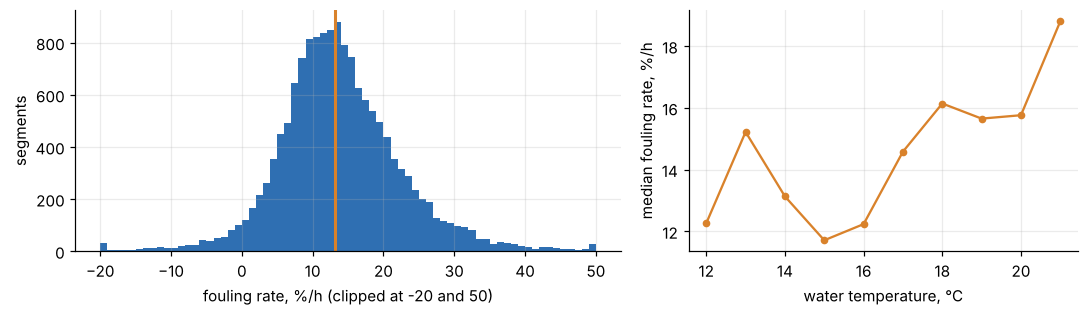

In [6]:
q = load("step2_segments.json")
print(f"{q['segments']:,} segments in {q['runs_with_segments']} runs and {q['episodes']} episodes; "
      f"median {q['minutes']['50%']} min long")
print(f"fouling rate: median {q['fouling_pct_h']['50%']:.1f} %/h, middle half {q['fouling_pct_h']['25%']:.1f}"
      f"-{q['fouling_pct_h']['75%']:.1f}; negative in {q['share_negative']:.1%} of segments")
print(f"one segment's own standard error is {q['median_se_over_abs_slope']:.0%} of its slope (median)")
fig, ax = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={"width_ratios": [1.4, 1]})
ax[0].hist(seg.fouling_pct_h.clip(-20, 50), bins=70, color=BLUE)
ax[0].axvline(seg.fouling_pct_h.median(), color=ORANGE, lw=2)
ax[0].set_xlabel("fouling rate, %/h (clipped at -20 and 50)"); ax[0].set_ylabel("segments")
by_t = seg.assign(tb=seg.temp_c.round()).groupby("tb").fouling_pct_h.median()
by_n = seg.assign(tb=seg.temp_c.round()).groupby("tb").size()
by_t = by_t[by_n >= 100]
ax[1].plot(by_t.index, by_t.values, "o-", color=ORANGE, ms=4)
ax[1].set_xlabel("water temperature, °C"); ax[1].set_ylabel("median fouling rate, %/h")
plt.tight_layout(); plt.show()

Two things to carry into the tests:

- **Each segment is noisy** — its own uncertainty is about a third of its slope — so no single
  segment says anything. The tests pool thousands, and ask whether they line up with a clock.
- **The rate moves with the seasons and between runs** (temperature, flow, element pair, the
  membrane's age). The tests take these out first in a *base model* — run levels, a slow trend
  within each episode, temperature, flow, segment length, element pair — and look only at what is
  left.

The next notebook asks the first question of what is left: does it follow the moon?